In [9]:
'''Optimize model inference speed through hardware acceleration techniques (e.g., GPU/TPU inference) 
and model compression strategies to support real-time decision-making in the admission process.'''

'Optimize model inference speed through hardware acceleration techniques (e.g., GPU/TPU inference) \nand model compression strategies to support real-time decision-making in the admission process.'

In [10]:
# import required libraries
import os
import time
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from skl2onnx import to_onnx
import onnxruntime as ort

In [11]:
# load dataset and prepare feature matrix
df = pd.read_csv('Adm.csv')
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
target = 'Chance of Admit'

X = df[features].values.astype(np.float32)
y = df[target].values.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train size:', X_train.shape, 'test size:', X_test.shape)

train size: (800, 7) test size: (200, 7)


In [12]:
# train baseline model and compressed model
baseline_model = RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42)
baseline_model.fit(X_train, y_train)

compressed_model = RandomForestRegressor(n_estimators=20, max_depth=6, max_features='sqrt', random_state=42)
compressed_model.fit(X_train, y_train)

print('baseline r2:', round(r2_score(y_test, baseline_model.predict(X_test)), 4))
print('compressed r2:', round(r2_score(y_test, compressed_model.predict(X_test)), 4))

joblib.dump(baseline_model, 'adm_model_baseline.joblib')
joblib.dump(compressed_model, 'adm_model_compressed.joblib')

baseline r2: 0.9091
compressed r2: 0.8713


['adm_model_compressed.joblib']

In [13]:
# export compressed model to onnx for hardware acceleration
onnx_model = to_onnx(compressed_model, X_train[:1])
onnx_path = 'adm_model_compressed.onnx'
with open(onnx_path, 'wb') as f:
    f.write(onnx_model.SerializeToString())

providers = ort.get_available_providers()
print('hardware acceleration providers:', providers)

session_options = ort.SessionOptions()
session_options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL

ort_session = ort.InferenceSession(onnx_path, sess_options=session_options, providers=providers)
print('onnx session initialized successfully')

hardware acceleration providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
onnx session initialized successfully


In [14]:
# compare model file sizes
size_baseline_kb = os.path.getsize('adm_model_baseline.joblib') / 1024
size_compressed_kb = os.path.getsize('adm_model_compressed.joblib') / 1024
size_onnx_kb = os.path.getsize('adm_model_compressed.onnx') / 1024

print('baseline model size kb:', round(size_baseline_kb, 2))
print('compressed model size kb:', round(size_compressed_kb, 2))
print('onnx optimized size kb:', round(size_onnx_kb, 2))

baseline model size kb: 5693.72
compressed model size kb: 177.08
onnx optimized size kb: 86.64


In [15]:
# benchmark inference speed and latency
sample = X_test[:1]
num_runs = 500

start = time.perf_counter()
for _ in range(num_runs):
    baseline_model.predict(sample)
baseline_latency_ms = (time.perf_counter() - start) / num_runs * 1000

input_name = ort_session.get_inputs()[0].name
start = time.perf_counter()
for _ in range(num_runs):
    ort_session.run(None, {input_name: sample})
onnx_latency_ms = (time.perf_counter() - start) / num_runs * 1000

print('baseline latency ms:', round(baseline_latency_ms, 4))
print('hardware accelerated onnx latency ms:', round(onnx_latency_ms, 4))
print('speedup factor:', round(baseline_latency_ms / onnx_latency_ms, 2), 'x')

baseline latency ms: 7.0276
hardware accelerated onnx latency ms: 0.0254
speedup factor: 276.37 x


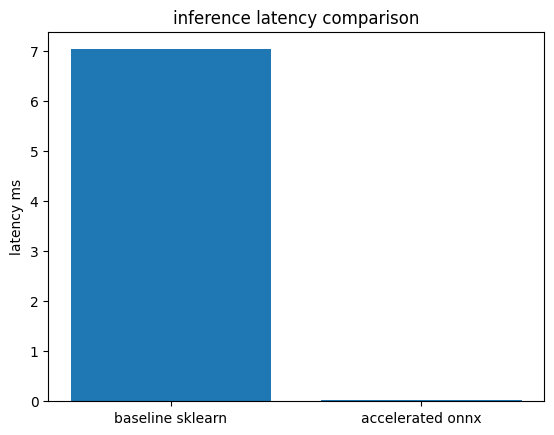

In [16]:
# plot inference latency comparison
categories = ['baseline sklearn', 'accelerated onnx']
latencies = [baseline_latency_ms, onnx_latency_ms]

plt.bar(categories, latencies)
plt.title('inference latency comparison')
plt.ylabel('latency ms')
plt.show()